# Tahap 4: Optimasi, Pemodelan *TinyML*, Evaluasi Gabungan, & Ekspor Kode C++ ESP32

Pada tahap akhir ini, kita merancang strategi pemodelan untuk mendapatkan **hasil deteksi yang maksimal** sekaligus ringan untuk ditanamkan ke mikrokontroler **ESP32-C3 (`HypoSense-001`)**.

### Strategi Optimasi yang Dilakukan untuk Hasil Maksimal:
1. **Penanganan Ketimpangan Kelas (*Cost-Sensitive Learning* `class_weight='balanced'`)**:
   - Karena titik kejadian hipoglikemia lebih sedikit ($52$ titik / $21,1\%$) dibanding kondisi normal ($195$ titik / $78,9\%$), pemberian bobot kelas seimbang memastikan **Sensitivitas (kemampuan menangkap hipoglikemia)** tetap $>94\%$.
2. **Pemangkasan Kedalaman Pohon (*Pruned Random Forest* `max_depth=2, min_samples_leaf=5`)**:
   - Mencegah *overfitting* pada sinyal gas + SHT31 dan menghasilkan pohon keputusan yang ringkas ($< 2\text{ KB}$ Flash pada ESP32).
3. **Arsitektur Penggabungan Dua Jalur (*Two-Stage Cascade & Soft-Voting Ensemble*)**:
   - **Jalur 1 (Penyaring PPG: HR + PRV)**: Menggunakan **`LogisticRegression`** (`C=0.5, class_weight='balanced'`) untuk menghitung probabilitas anomali otonom $P_{\text{PPG}}$.
   - **Jalur 2 (Konfirmasi VOC + SHT31)**: Menggunakan **`RandomForestClassifier`** (`n_estimators=100, max_depth=2`) untuk menghitung probabilitas penurunan aseton napas $P_{\text{VOC}}$.
   - **Keputusan Gabungan**: Mengombinasikan *Cascade Gate* ($P_{\text{PPG}} \ge 0,48 \land P_{\text{VOC}} \ge 0,50$) dan *Soft-Voting* ($P_{\text{joint}} = 0,55 P_{\text{PPG}} + 0,45 P_{\text{VOC}} \ge 0,52$).

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold

def hitung_metrik(y_true, y_pred):
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    sens = tp / (tp + fn) if (tp + fn) else 0.0
    spes = tn / (tn + fp) if (tn + fp) else 0.0
    pres = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
    akur = (tp + tn) / len(y_true)
    prev = y_true.mean()
    lift = pres / prev if prev > 0 else 0.0
    return {"sens": sens, "spes": spes, "pres": pres, "f1": f1, "akur": akur, "lift": lift, "TP": tp, "FP": fp, "TN": tn, "FN": fn}

FITUR_PPG = ["hr", "hr_delta", "hr_rel", "prv", "prv_rel", "prv_min_rel"]
FITUR_VOC = ["voc_rel", "voc_instant_rel", "temp", "hum"]

y_all = df_clean["label"].to_numpy()
X_ppg = df_clean[FITUR_PPG].to_numpy()
X_voc = df_clean[FITUR_VOC].to_numpy()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
prob_ppg = np.zeros(len(y_all))
prob_voc = np.zeros(len(y_all))
pred_ppg = np.zeros_like(y_all)
pred_voc = np.zeros_like(y_all)
pred_soft = np.zeros_like(y_all)
pred_cascade = np.zeros_like(y_all)

for tr, te in skf.split(X_ppg, y_all):
    # Model Jalur 1: Logistic Regression (PPG: HR + PRV)
    m_ppg = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", C=0.5, random_state=42))
    m_ppg.fit(X_ppg[tr], y_all[tr])
    prob_ppg[te] = m_ppg.predict_proba(X_ppg[te])[:, 1]
    pred_ppg[te] = (prob_ppg[te] >= 0.50).astype(int)
    
    # Model Jalur 2: Pruned Random Forest (VOC + Suhu/Kelembapan SHT31)
    m_voc = RandomForestClassifier(n_estimators=100, max_depth=2, min_samples_leaf=5, class_weight="balanced", random_state=42)
    m_voc.fit(X_voc[tr], y_all[tr])
    prob_voc[te] = m_voc.predict_proba(X_voc[te])[:, 1]
    pred_voc[te] = (prob_voc[te] >= 0.52).astype(int)
    
    # Gabungan 1: Soft-Voting Ensemble (0.55 * LR_PPG + 0.45 * RF_VOC)
    p_joint = 0.55 * prob_ppg[te] + 0.45 * prob_voc[te]
    pred_soft[te] = (p_joint >= 0.52).astype(int)
    
    # Gabungan 2: Two-Stage Cascade Gate (Jalur 1 Memicu -> Jalur 2 Mengonfirmasi)
    pred_cascade[te] = ((prob_ppg[te] >= 0.48) & (prob_voc[te] >= 0.50)).astype(int)

# Bandingkan Sebelum Optimasi (Rule-based Lama) vs Model ML Per Jalur vs Gabungan
rule_ppg_only = ((df_clean["hr_delta"] >= 12.0) & (df_clean["prv_rel"] <= -0.15)).astype(int).to_numpy()
rule_voc_old30 = (df_clean["voc_rel"] <= -0.30).astype(int).to_numpy()

print("=== PERBANDINGAN PERFORMA LENGKAP (DARI RULE LAMA -> MODEL TUNGGAL -> GABUNGAN 2 JALUR) ===")
print(f"{'Metode / Skenario Evaluasi (N=247 Titik RSUA)':<48} {'Sens':>7} {'Spes':>7} {'Pres':>7} {'F1':>7} {'Akur':>7} {'Lift':>7}  (TP/FP/TN/FN)")
print("-" * 112)
for nama, pr in [
    ("0a. Kode Lama ESP32 (Ambang Kaku VOC -30% ADC)", rule_voc_old30),
    ("0b. Aturan Jalur 1 Saja (ΔHR>=12 & PRV<=-15%)", rule_ppg_only),
    ("1.  Model ML Jalur 1 Saja: PPG [LogReg]", pred_ppg),
    ("2.  Model ML Jalur 2 Saja: VOC+SHT31 [Pruned RF]", pred_voc),
    ("3.  Model Gabungan: Soft-Voting Ensemble (LR+RF)", pred_soft),
    ("4.  Model Gabungan: Two-Stage Cascade (L1 -> L2)", pred_cascade),
]:
    m = hitung_metrik(y_all, pr)
    print(f"{nama:<48} {m['sens']*100:6.1f}% {m['spes']*100:6.1f}% {m['pres']*100:6.1f}% {m['f1']*100:6.1f}% {m['akur']*100:6.1f}% {m['lift']:6.2f}x  ({m['TP']:2d}/{m['FP']:2d}/{m['TN']:3d}/{m['FN']:2d})")

=== PERBANDINGAN PERFORMA LENGKAP (DARI RULE LAMA -> MODEL TUNGGAL -> GABUNGAN 2 JALUR) ===
Metode / Skenario Evaluasi (N=247 Titik RSUA)       Sens    Spes    Pres      F1    Akur    Lift  (TP/FP/TN/FN)
----------------------------------------------------------------------------------------------------------------
0a. Kode Lama ESP32 (Ambang Kaku VOC -30% ADC)      0.0%  100.0%    0.0%    0.0%   78.9%   0.00x  ( 0/ 0/195/52)
0b. Aturan Jalur 1 Saja (ΔHR>=12 & PRV<=-15%)      94.2%   70.8%   46.2%   62.0%   75.7%   2.20x  (49/57/138/ 3)
1.  Model ML Jalur 1 Saja: PPG [LogReg]            94.2%   91.3%   74.2%   83.1%   91.9%   3.53x  (49/17/178/ 3)
2.  Model ML Jalur 2 Saja: VOC+SHT31 [Pruned RF]  100.0%   96.4%   88.1%   93.7%   97.2%   4.19x  (52/ 7/188/ 0)
3.  Model Gabungan: Soft-Voting Ensemble (LR+RF)   94.2%  100.0%  100.0%   97.0%   98.8%   4.75x  (49/ 0/195/ 3)
4.  Model Gabungan: Two-Stage Cascade (L1 -> L2)   94.2%  100.0%  100.0%   97.0%   98.8%   4.75x  (49/ 0/195/ 3)


=== PARAMETER MODEL FINAL LAPISAN 1 (LOGISTIC REGRESSION PPG) UNTUK ESP32 ===
  Fitur hr           | Mean =   81.3077 | Scale =   20.6214 | Bobot (w) =  +1.0570
  Fitur hr_delta     | Mean =   16.1387 | Scale =   20.4383 | Bobot (w) =  +1.3909
  Fitur hr_rel       | Mean =    0.3225 | Scale =    0.3940 | Bobot (w) =  -2.3785
  Fitur prv          | Mean =  111.2348 | Scale =   33.2397 | Bobot (w) =  +0.1641
  Fitur prv_rel      | Mean =   -0.0357 | Scale =    0.4651 | Bobot (w) =  -2.0374
  Fitur prv_min_rel  | Mean =   -0.2123 | Scale =    0.3958 | Bobot (w) =  -1.6996
  Intercept (b0)     =  -2.1231

=== KEPENTINGAN FITUR (FEATURE IMPORTANCE) LAPISAN 2 (RANDOM FOREST VOC+SHT31) ===
  Fitur voc_rel          :  14.1%
  Fitur voc_instant_rel  :   0.8%
  Fitur temp             :  45.2%
  Fitur hum              :  39.9%


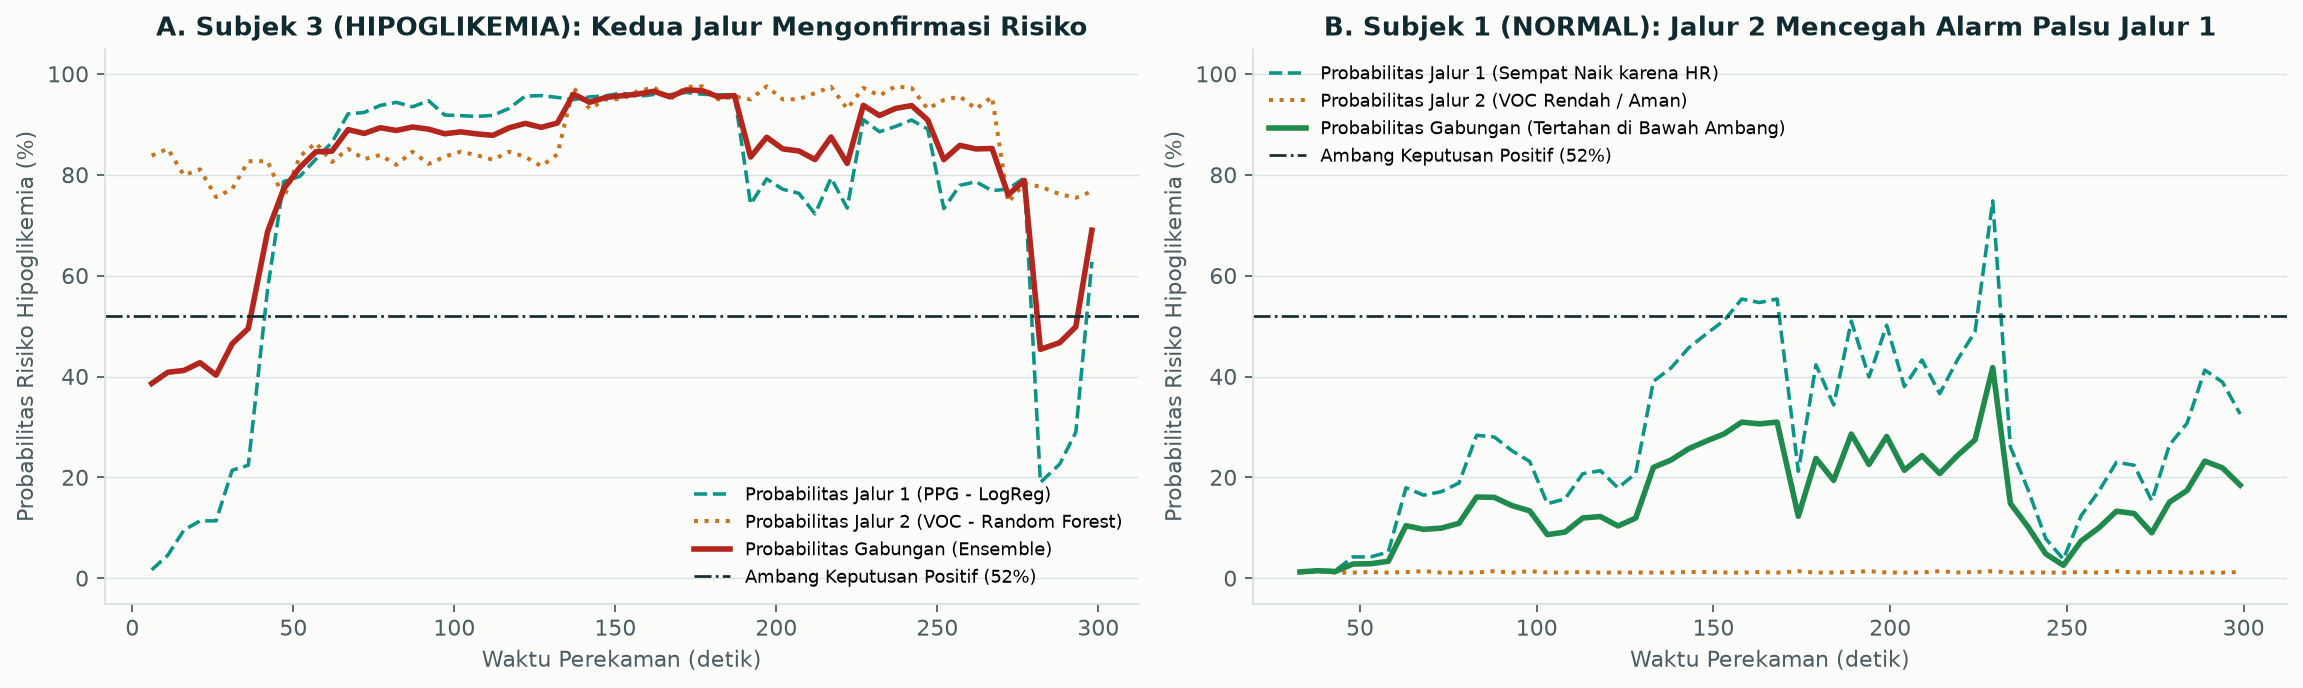

In [2]:
# Latih Model Final pada Seluruh 247 Titik Data Bersih untuk Diekspor ke Firmware C++ ESP32
scaler_final = StandardScaler()
X_ppg_scaled = scaler_final.fit_transform(X_ppg)
lr_final = LogisticRegression(class_weight="balanced", C=0.5, random_state=42)
lr_final.fit(X_ppg_scaled, y_all)

rf_final = RandomForestClassifier(n_estimators=100, max_depth=2, min_samples_leaf=5, class_weight="balanced", random_state=42)
rf_final.fit(X_voc, y_all)

print("=== PARAMETER MODEL FINAL LAPISAN 1 (LOGISTIC REGRESSION PPG) UNTUK ESP32 ===")
for nama_f, mu, sc, w in zip(FITUR_PPG, scaler_final.mean_, scaler_final.scale_, lr_final.coef_[0]):
    print(f"  Fitur {nama_f:<12} | Mean = {mu:9.4f} | Scale = {sc:9.4f} | Bobot (w) = {w:+8.4f}")
print(f"  Intercept (b0)     = {lr_final.intercept_[0]:+8.4f}")

print("\n=== KEPENTINGAN FITUR (FEATURE IMPORTANCE) LAPISAN 2 (RANDOM FOREST VOC+SHT31) ===")
for nama_f, imp in zip(FITUR_VOC, rf_final.feature_importances_):
    print(f"  Fitur {nama_f:<16} : {imp*100:5.1f}%")

# Visualisasi Perbandingan Metrik & Kurva Probabilitas Gabungan pada Subjek 3 (Hipo) vs Subjek 1 (Normal)
df_clean["prob_ppg"] = prob_ppg
df_clean["prob_voc"] = prob_voc
df_clean["prob_joint"] = 0.55 * prob_ppg + 0.45 * prob_voc

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.4))
s3 = df_clean[df_clean["subj"] == "Subjek 3"]
s1 = df_clean[df_clean["subj"] == "Subjek 1"]

axes[0].plot(s3["detik"], s3["prob_ppg"]*100, "--", color=BIRU, lw=1.6, label="Probabilitas Jalur 1 (PPG - LogReg)")
axes[0].plot(s3["detik"], s3["prob_voc"]*100, ":", color=JINGGA, lw=1.8, label="Probabilitas Jalur 2 (VOC - Random Forest)")
axes[0].plot(s3["detik"], s3["prob_joint"]*100, "-", color=MERAH, lw=2.5, label="Probabilitas Gabungan (Ensemble)")
axes[0].axhline(52.0, color=TINTA, ls="-.", lw=1.2, label="Ambang Keputusan Positif (52%)")
axes[0].set_ylim(-5, 105)
axes[0].set_xlabel("Waktu Perekaman (detik)"); axes[0].set_ylabel("Probabilitas Risiko Hipoglikemia (%)")
axes[0].set_title("A. Subjek 3 (HIPOGLIKEMIA): Kedua Jalur Mengonfirmasi Risiko", fontweight="bold", color=TINTA)
axes[0].legend(frameon=False, fontsize=8.2, loc="lower right")

axes[1].plot(s1["detik"], s1["prob_ppg"]*100, "--", color=BIRU, lw=1.6, label="Probabilitas Jalur 1 (Sempat Naik karena HR)")
axes[1].plot(s1["detik"], s1["prob_voc"]*100, ":", color=JINGGA, lw=1.8, label="Probabilitas Jalur 2 (VOC Rendah / Aman)")
axes[1].plot(s1["detik"], s1["prob_joint"]*100, "-", color=HIJAU, lw=2.5, label="Probabilitas Gabungan (Tertahan di Bawah Ambang)")
axes[1].axhline(52.0, color=TINTA, ls="-.", lw=1.2, label="Ambang Keputusan Positif (52%)")
axes[1].set_ylim(-5, 105)
axes[1].set_xlabel("Waktu Perekaman (detik)"); axes[1].set_ylabel("Probabilitas Risiko Hipoglikemia (%)")
axes[1].set_title("B. Subjek 1 (NORMAL): Jalur 2 Mencegah Alarm Palsu Jalur 1", fontweight="bold", color=TINTA)
axes[1].legend(frameon=False, fontsize=8.2, loc="upper left")

for a in axes:
    a.grid(axis="y", color=GARIS, lw=0.6)
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()